In [1]:
import pandas as pd

B_Cell_transcripts = "/mnt/data_sda/jdearborn/scratch/Imm_cell_rMATS/data_labeling/results/stringtie_out/dominant_isoforms/B_Cell_transcripts.tsv"
T_Cell_transcripts = "/mnt/data_sda/jdearborn/scratch/Imm_cell_rMATS/data_labeling/results/stringtie_out/dominant_isoforms/T_Cell_transcripts.tsv"
Macrophage_transcripts = "/mnt/data_sda/jdearborn/scratch/Imm_cell_rMATS/data_labeling/results/stringtie_out/dominant_isoforms/Macrophage_transcripts.tsv"

transcripts_files = {
    "B_Cell": B_Cell_transcripts,
    "T_Cell": T_Cell_transcripts,
    "Macrophage": Macrophage_transcripts,
}

for cell_type, path in transcripts_files.items():
    tx = pd.read_csv(path, sep="\t")
    print(f"{cell_type} transcripts: {len(tx)}")

    WINDOW = 524_288
    STRIDE = 196_608

    def count_windows(start, end):
        L = end - start
        if L < WINDOW:
            return 0
        return (L - WINDOW) // STRIDE + 1

    tx["n_windows"] = tx.apply(lambda r: count_windows(r.Start, r.End), axis=1)

    print("Total transcripts:", len(tx))
    print("Transcripts with ≥1 window:", (tx.n_windows > 0).sum())
    print("Total windows:", tx.n_windows.sum())

    print("\nTop contributors:")
    print(tx.sort_values("n_windows", ascending=False).head(10))


B_Cell transcripts: 31523
Total transcripts: 31523
Transcripts with ≥1 window: 23
Total windows: 34

Top contributors:
      Chromosome      Start        End Strand        transcript_id  \
8983       chr14   22019711   23056085      +   B_Cell_agg.23871.1   
6322       chr12   41024328   41955242      +   B_Cell_agg.21268.5   
21766       chr5   81020751   81795295      +    B_Cell_agg.8797.2   
724         chr1   61808119   62642284      +     B_Cell_agg.557.1   
24764       chr6  144028279  144781977      -   B_Cell_agg.11773.1   
23258       chr6   33249084   33973979      +   B_Cell_agg.10217.1   
26194       chr7   91711601   92445535      +   B_Cell_agg.13238.2   
11742      chr16   42907651   43642602      +  B_Cell_agg.26689.12   
8845       chr14    9550091   10453458      -   B_Cell_agg.23771.1   
2129        chr1  178951959  179518034      -    B_Cell_agg.2084.1   

                gene_id  n_windows  
8983   B_Cell_agg.23871          3  
6322   B_Cell_agg.21268          3  

In [2]:
T_CELL_BED = "/mnt/data_sda/jdearborn/scratch/Imm_cell_rMATS/data_labeling/outputs_soft_per_sample/soft/T_Cell_soft_psi_0.bed"

bed = pd.read_csv(
    T_CELL_BED,
    sep="\t",
    names=["Chrom","Start","End","p_exon"]
)

psi_bp = (bed.End - bed.Start).sum()
tx_bp = (tx.End - tx.Start).sum()

print("PSI bp:", psi_bp)
print("Transcript bp:", tx_bp)
print("Fraction PSI-labeled:", psi_bp / tx_bp)


PSI bp: 505666343
Transcript bp: 611055512
Fraction PSI-labeled: 0.8275293047352463


In [3]:
bed["mid"] = (bed.Start + bed.End) // 2

merged = bed.merge(
    tx[["Chromosome","Start","End","transcript_id"]],
    left_on="Chrom",
    right_on="Chromosome",
    how="left"
)

merged["tx_mid"] = (merged.Start_y + merged.End_y) // 2
merged["dist_from_tx_mid"] = merged.mid - merged.tx_mid

merged["dist_from_tx_mid"].abs().describe()


count    4.671912e+08
mean     4.579566e+07
std      3.657383e+07
min      0.000000e+00
25%      1.558733e+07
50%      3.728451e+07
75%      6.929724e+07
max      1.916892e+08
Name: dist_from_tx_mid, dtype: float64

In [11]:
import numpy as np
from pathlib import Path
import pandas as pd

shard_dir = "/mnt/data_sda/jdearborn/scratch/Imm_cell_rMATS/data_labeling/results/labelled_data/windowed_multitask/train"

shard_path = Path(shard_dir) / "shard_0000.npz"
shard = np.load(shard_path, allow_pickle=True)

print("Keys:", shard.files)
print("Num examples:", shard["sequence"].shape[0])


Keys: ['sequence', 'targets', 'mask', 'cell_type', 'bed_path', 'chrom', 'window_start', 'window_end', 'has_signal']
Num examples: 256


In [12]:
for k in shard.files:
    print(k, shard[k].shape if hasattr(shard[k], "shape") else type(shard[k]))

sequence (256, 524288, 4)
targets (256, 16384, 3)
mask (256, 16384)
cell_type (256,)
bed_path (256,)
chrom (256,)
window_start (256,)
window_end (256,)
has_signal (256,)


In [14]:
targets = shard["targets"]

# Sum per task per example
task_sums = targets.sum(axis=1)   # shape (N, n_tasks)

nonzero_tasks = (task_sums > 0).sum(axis=1)

print("Unique #nonzero tasks per example:", np.unique(nonzero_tasks))


Unique #nonzero tasks per example: [0 1]


In [21]:
cell_types = shard["cell_type"]
targets = shard["targets"]

for i in range(5):
    ct = cell_types[i]
    active = np.where(targets[i].sum(axis=0) > 0)[0]
    print(i, ct, active)


0 B_Cell [0]
1 B_Cell [0]
2 B_Cell []
3 B_Cell [0]
4 B_Cell [0]


In [16]:
mask = shard["mask"]
targets = shard["targets"]

violations = (targets.sum(axis=2) > 0) & (mask == 0)
print("Violations:", violations.sum())


Violations: 0


In [23]:
masked_fraction = pd.Series(mask.sum(axis=1) / mask.shape[1])
masked_fraction.describe()


count    256.000000
mean       0.190097
std        0.235850
min        0.000000
25%        0.002518
50%        0.086792
75%        0.339020
max        1.000000
dtype: float64

In [24]:
(mask.sum(axis=1) > 0).mean()


0.8359375

In [27]:
rows = []
for i in range(len(shard["cell_type"])):
    rows.append({
        "cell_type": shard["cell_type"][i],
        "has_signal": shard["has_signal"][i]
    })

print(
pd.crosstab(
    pd.Series([r["cell_type"] for r in rows]),
    pd.Series([r["has_signal"] for r in rows]),
    normalize="index"
))

col_0        0.0       1.0
row_0                     
B_Cell  0.164062  0.835938


In [18]:
starts = shard["window_start"]
ends = shard["window_end"]

lengths = ends - starts
lengths.min(), lengths.max()


(524288, 524288)

In [22]:
df = pd.DataFrame({
    "chrom": shard["chrom"],
    "start": starts
})

print(df.sort_values(["chrom", "start"]).groupby("chrom")["start"].diff().dropna().value_counts().head()
)

start
262144.0    255
Name: count, dtype: int64


In [10]:
cell_types = shard["cell_type"]
df = pd.DataFrame({
    "cell_type": cell_types,
    "chrom": shard["chrom"],
    "start": shard["window_start"],
    "end": shard["window_end"],
})

df["cell_type"].value_counts()


cell_type
B_Cell    256
Name: count, dtype: int64

In [4]:
import numpy as np



d = np.load(f"{shard_dir}/shard_0000.npz")

print("Keys:", d.files)
print("sequence:", d["sequence"].shape)
print("targets:", d["targets"].shape)
print("mask:", d["mask"].shape)
print("cell_type:", d["cell_type"][:5])
print("chrom:", d["chrom"][:5])


Keys: ['sequence', 'targets', 'mask', 'cell_type', 'bed_path', 'chrom', 'window_start', 'window_end']
sequence: (256, 524288, 4)
targets: (256, 16384, 3)
mask: (256, 16384)
cell_type: ['B_Cell' 'B_Cell' 'B_Cell' 'B_Cell' 'B_Cell']
chrom: ['chr1' 'chr1' 'chr1' 'chr1' 'chr1']


In [5]:
i = 0
chrom = d["chrom"][i]
start = d["window_start"][i]
end   = d["window_end"][i]

print(chrom, start, end)


chr1 3269650 3793938


In [6]:
BIN_SIZE = 32
b = 5000   # arbitrary bin

bin_start = start + b * BIN_SIZE
bin_end   = bin_start + BIN_SIZE

print("Bin", b, "→", f"{chrom}:{bin_start}-{bin_end}")
print("Mask:", d["mask"][i, b])
print("Targets:", d["targets"][i, b, :])


Bin 5000 → chr1:3429650-3429682
Mask: 0.0
Targets: [0. 0. 0.]


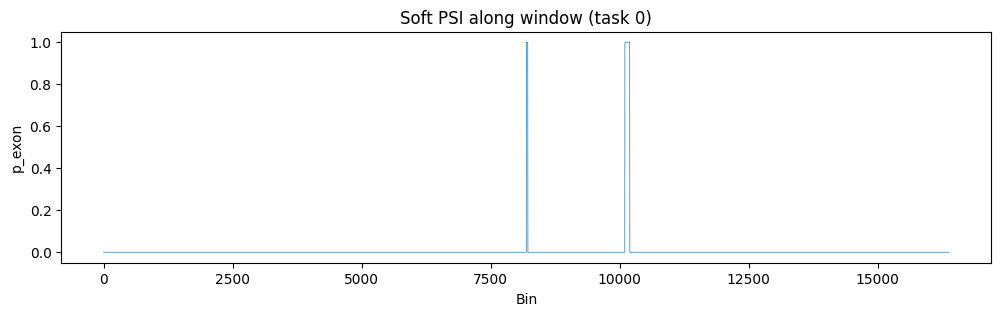

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,3))
plt.plot(d["targets"][i,:,0], lw=0.5)
plt.title("Soft PSI along window (task 0)")
plt.xlabel("Bin")
plt.ylabel("p_exon")
plt.show()


In [8]:
usable = d["targets"][i, 5120:-5120, :]
usable_mask = d["mask"][i, 5120:-5120]
print("Usable bins:", usable.shape[0])  # should be 6144
print("Masked fraction:", usable_mask.mean())


Usable bins: 6144
Masked fraction: 0.020182291
